In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF


In [2]:
real = pd.read_csv("True.csv")
fake = pd.read_csv("Fake.csv")


In [3]:
real_text = real["text"].head(2000).fillna("")
fake_text = fake["text"].head(2000).fillna("")

In [4]:
# Convert text into TF-IDF features
vectorizer = TfidfVectorizer(stop_words="english", max_features=3000, min_df=2)

real_matrix = vectorizer.fit_transform(real_text)
fake_matrix = vectorizer.transform(fake_text)


In [5]:
# Apply NMF topic modelling
real_nmf = NMF(n_components=5, random_state=42, max_iter=200)
fake_nmf = NMF(n_components=5, random_state=42, max_iter=200)

real_topics = real_nmf.fit_transform(real_matrix)
fake_topics = fake_nmf.fit_transform(fake_matrix)

words = vectorizer.get_feature_names_out()


In [6]:
# Display top words 
def show_topics(model, title):
    print("\n" + title)
    print("Topic 1:", ", ".join(words[model.components_[0].argsort()[-10:][::-1]]))
    print("Topic 2:", ", ".join(words[model.components_[1].argsort()[-10:][::-1]]))
    print("Topic 3:", ", ".join(words[model.components_[2].argsort()[-10:][::-1]]))
    print("Topic 4:", ", ".join(words[model.components_[3].argsort()[-10:][::-1]]))
    print("Topic 5:", ", ".join(words[model.components_[4].argsort()[-10:][::-1]]))

show_topics(real_nmf, "REAL NEWS TOPICS")
show_topics(fake_nmf, "FAKE NEWS TOPICS")



REAL NEWS TOPICS
Topic 1: trump, russian, russia, campaign, mueller, manafort, election, flynn, said, investigation
Topic 2: tax, percent, senate, rate, republicans, corporate, house, plan, republican, taxes
Topic 3: north, korea, china, nuclear, trump, iran, said, tillerson, united, sanctions
Topic 4: said, trump, house, republican, senate, moore, president, congress, democratic, white
Topic 5: edt, ly, bit, realdonaldtrump, est, statements, 2jpexyr, 2jbh4lu, link, edited

FAKE NEWS TOPICS
Topic 1: trump, white, just, president, donald, world, america, obama, house, time
Topic 2: comey, fbi, investigation, james, trump, director, firing, fired, russia, testimony
Topic 3: com, twitter, realdonaldtrump, 2017, june, april, july, august, fake, 29
Topic 4: people, like, just, video, care, right, know, don, health, republicans
Topic 5: flynn, russia, russian, trump, kushner, mueller, putin, investigation, jr, campaign


In [7]:
# Calculate average topic relevance
real_relevance = real_topics.mean(axis=0)
fake_relevance = fake_topics.mean(axis=0)

result = pd.DataFrame({
    "Topic": ["Topic 1", "Topic 2", "Topic 3", "Topic 4", "Topic 5"], "Real News": real_relevance, "Fake News": fake_relevance})

print("\nAverage Topic Relevance:")
print(result.round(3))



Average Topic Relevance:
     Topic  Real News  Fake News
0  Topic 1      0.024      0.045
1  Topic 2      0.031      0.016
2  Topic 3      0.031      0.029
3  Topic 4      0.056      0.042
4  Topic 5      0.010      0.027


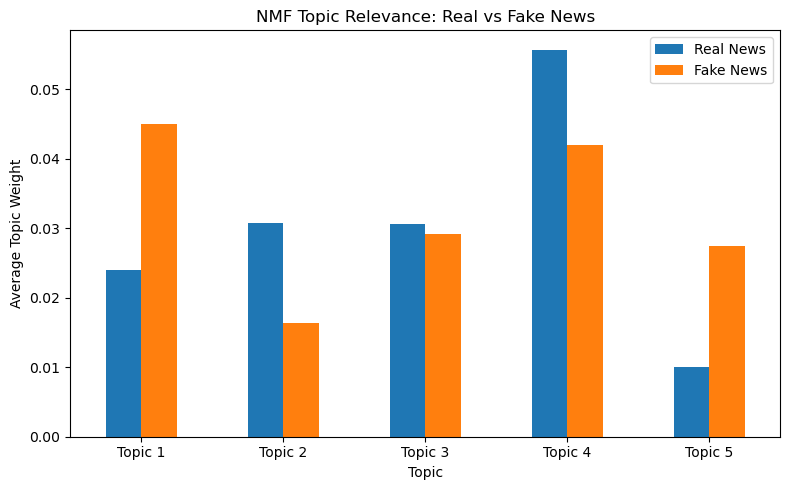

In [8]:
# Compare topic relevance
result.plot(x="Topic", y=["Real News", "Fake News"], kind="bar", figsize=(8, 5))

plt.title("NMF Topic Relevance: Real vs Fake News")
plt.ylabel("Average Topic Weight")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
